# Customer churn: data quality and exploratory analysis
## 1. Executive introduction
EdVyro Data Analytics Internship - Task 02. This notebook audits the supplied synthetic customer snapshot, produces a validated local CSV, and examines descriptive churn associations. All published outputs are aggregate tables or binned visualizations. No customer-level records are displayed.

**Data access:** provide the authorized input as described in `data/raw/README.md`. Raw and cleaned CSVs are excluded from Git. Cleaned-CSV delivery remains pending permission or an approved private route.

## 2. Business problem
Which customer groups should a fictional subscription retention team investigate first? Report evidence and uncertainty without claiming that contract, price, or support contacts cause churn. The denominator is the supplied customer snapshot; the observation window is unknown.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Run from repository root or notebooks directory"
sys.path.insert(0, str(ROOT))
import json
import pandas as pd
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
from IPython.display import display, Markdown, Image
from src.data_cleaning import load_data, clean_data
from src.data_validation import profile_columns, validation_checks, iqr_audit, quality_summary, NUMERIC
from src.analysis import generate, segment_table, findings, recommendations, LIMITATIONS, FIGURES
raw = load_data()
print("Input loaded; aggregate-only output policy active.")

Input loaded; aggregate-only output policy active.


## 3. Dataset overview
The official curriculum calls this milestone 2, while its task kit is named `data-analytics-task-1`. The supplied brief links this customer churn CSV. No newer matching source was found in the workspace or accessible Downloads tree. On 22 October 2026 a live HTTPS download from the official dataset endpoint had exactly the same SHA-256 as the supplied file. Accessibility does not establish redistribution rights. The exact input checksum and source URLs are recorded below.

In [2]:
provenance = json.loads((ROOT / "src/provenance.json").read_text())
display(pd.Series({"rows": len(raw), "columns": len(raw.columns),
                   "source_sha256": provenance["source_sha256"],
                   "official_task": provenance["official_task_url"]}).to_frame("value"))

,value
rows,15
columns,11
source_sha256,1d5048cad41e8abbefd5fab04cc7dd6579234a292a8f59f85d7d072f37fabdce
official_task,https://edvyro.in/datasets/task-kits/data-analytics-task-1


## 4. Data dictionary
Definitions follow actual CSV field names. INR and the prior-90-day support-ticket window come from a tentative generic-guide mapping. The guide's monthly/quarterly/annual contracts conflict with the supplied CSV; actual CSV labels are retained.

In [3]:
display(profile_columns(raw)[["column", "definition"]])

,column,definition
0,CustomerID,Synthetic record identifier; never a numeric measure.
1,Gender,Recorded gender label; sample labels are not an exhaustive real-world taxonomy.
2,Age,Customer age in years (inferred from field name).
3,TenureMonths,Completed months since signup (guide mapping).
4,SubscriptionType,Recorded subscription tier; individual subscribed services are unavailable.
5,MonthlyCharges,"Fictional monthly amount; INR per guide mapping, not verified by CSV metadata."
6,TotalCharges,Recorded cumulative amount; historical billing semantics are not supplied.
7,ContractType,Actual CSV contract label; retain Month-to-Month / One Year / Two Year.
8,SupportTickets,"Support ticket count; previous 90 days per guide mapping, unverified in CSV."
9,PaymentMethod,Recorded payment method.


## 5. Initial data inspection
Inspect schema and aggregate dimensions without exposing a `head()` preview, customer IDs, or individual records.

In [4]:
display(profile_columns(raw)[["column", "dtype", "unique_nonmissing"]])

,column,dtype,unique_nonmissing
0,CustomerID,str,15
1,Gender,str,2
2,Age,int64,15
3,TenureMonths,int64,15
4,SubscriptionType,str,3
5,MonthlyCharges,float64,3
6,TotalCharges,float64,15
7,ContractType,str,3
8,SupportTickets,int64,7
9,PaymentMethod,str,4


## 6. Data-quality profiling
Review required fields, domain membership, impossible numeric values and logical consistency. Unknown categories are rejected under this sample contract; they may be legitimate in future data and require owner review. Age bounds and current-rate billing equality are review diagnostics, not authoritative business restrictions.

In [5]:
display(validation_checks(raw))

,check,violations,severity,status
0,Nonempty dataset,0,error,PASS
1,Missing required cells,0,error,PASS
2,Blank strings,0,error,PASS
3,Exact duplicate rows (excess),0,error,PASS
4,Duplicate customer IDs (excess),0,error,PASS
5,Identifier format,0,error,PASS
6,Unparseable numeric cells,0,error,PASS
7,Nonfinite numeric cells,0,error,PASS
8,Negative numeric cells,0,error,PASS
9,Noninteger count/age cells,0,error,PASS


## 7. Missing-value analysis
Count missing values per column and report their share of all rows. Also check whitespace-only strings. No unknown value is automatically converted into zero.

In [6]:
display(profile_columns(raw)[["column", "missing", "missing_pct"]])

,column,missing,missing_pct
0,CustomerID,0,0.0
1,Gender,0,0.0
2,Age,0,0.0
3,TenureMonths,0,0.0
4,SubscriptionType,0,0.0
5,MonthlyCharges,0,0.0
6,TotalCharges,0,0.0
7,ContractType,0,0.0
8,SupportTickets,0,0.0
9,PaymentMethod,0,0.0


## 8. Duplicate detection
An excess count excludes the first occurrence. Only fully identical records can be removed automatically; different records sharing an identifier must be resolved by the data owner.

In [7]:
display(pd.Series({"exact duplicate excess": int(raw.duplicated().sum()),
                   "duplicate ID excess": int(raw.CustomerID.duplicated().sum())}).to_frame("count"))

,count
exact duplicate excess,0
duplicate ID excess,0


## 9. Outlier analysis
Use 1.5 times IQR fences with pandas linear quantiles on numeric fields. Flags prompt review; no extreme is automatically deleted or capped. Statistical fences do not define valid business ranges.

In [8]:
display(iqr_audit(raw))

,column,q1,q3,lower_fence,upper_fence,flagged_rows
0,Age,30.00,47.00,4.50,72.50,0
1,TenureMonths,7.00,27.00,-23.00,57.00,0
2,MonthlyCharges,49.99,114.99,-47.51,212.49,0
3,TotalCharges,449.91,3209.73,-3689.82,7349.46,0
4,SupportTickets,1.00,4.00,-3.50,8.50,0


## 10. Cleaning decisions
The source already meets the implemented quality rules. Preserve valid behavior and churn labels. The log records detection, action, justification, rows affected and validation result. A zero count means that operation was evaluated but changed no rows. Counts across actions need not represent distinct customers.

In [9]:
clean, decisions = clean_data(raw)
display(decisions)

,issue,detection_method,action,justification,rows_affected,validation_result
0,CustomerID: formatting,Compare trimmed identifier,Trim identifier whitespace; blank to missing,Preserve identifier case and do not guess unknown categories.,0,PASS
1,Gender: formatting,Trim and case-insensitive comparison with supplied labels,Trim surrounding whitespace; canonicalize known labels; blank to missing,Preserve identifier case and do not guess unknown categories.,0,PASS
2,SubscriptionType: formatting,Trim and case-insensitive comparison with supplied labels,Trim surrounding whitespace; canonicalize known labels; blank to missing,Preserve identifier case and do not guess unknown categories.,0,PASS
3,ContractType: formatting,Trim and case-insensitive comparison with supplied labels,Trim surrounding whitespace; canonicalize known labels; blank to missing,Preserve identifier case and do not guess unknown categories.,0,PASS
4,PaymentMethod: formatting,Trim and case-insensitive comparison with supplied labels,Trim surrounding whitespace; canonicalize known labels; blank to missing,Preserve identifier case and do not guess unknown categories.,0,PASS
5,Churn: formatting,Trim and case-insensitive comparison with supplied labels,Trim surrounding whitespace; canonicalize known labels; blank to missing,Preserve identifier case and do not guess unknown categories.,0,PASS
6,Age: numeric type,Parse numbers and check integer fields,Use explicit numeric dtype,Invalid numeric text fails instead of becoming an imputed value.,0,PASS
7,TenureMonths: numeric type,Parse numbers and check integer fields,Use explicit numeric dtype,Invalid numeric text fails instead of becoming an imputed value.,0,PASS
8,MonthlyCharges: numeric type,Parse numbers and check integer fields,Use explicit numeric dtype,Invalid numeric text fails instead of becoming an imputed value.,0,PASS
9,TotalCharges: numeric type,Parse numbers and check integer fields,Use explicit numeric dtype,Invalid numeric text fails instead of becoming an imputed value.,0,PASS


## 11. Cleaning execution
Run the reusable pipeline, reopen the CSV for integrity checks, and regenerate reports and figures. The raw file is never overwritten. The cleaned file is written locally to `data/processed/customer_churn_cleaned.csv` and stays excluded from the public commit.

In [10]:
metrics = generate()
reopened = load_data(ROOT / "data/processed/customer_churn_cleaned.csv")
pd.testing.assert_frame_equal(clean, reopened, check_dtype=False)
display(pd.DataFrame({"before": quality_summary(raw), "after": quality_summary(clean)}))

{
  "customers": 15,
  "churned": 7,
  "churn_pct": 46.666666666666664,
  "retained": 8,
  "mean_tenure_churned": 7.0,
  "mean_tenure_retained": 29.125,
  "mean_monthly_churned": 58.56142857142857,
  "mean_monthly_retained": 107.49000000000001,
  "mean_tickets_churned": 4.285714285714286,
  "mean_tickets_retained": 1.0
}


,before,after
rows,15,15
columns,11,11
missing_cells,0,0
exact_duplicates_excess,0,0
duplicate_IDs_excess,0,0
validation_error_violations,0,0
IQR_flags_across_columns,0,0


## 12. Validation results
All required fields must pass. Target review checks require both classes for this exploration, without imposing an invented acceptable population churn rate. Review issues remain visible for human interpretation.

In [11]:
checks = validation_checks(clean)
assert checks.status.eq("PASS").all(), "Investigate validation or review issues"
assert raw.equals(clean), "Supplied snapshot should be preserved without value changes"
display(checks)

,check,violations,severity,status
0,Nonempty dataset,0,error,PASS
1,Missing required cells,0,error,PASS
2,Blank strings,0,error,PASS
3,Exact duplicate rows (excess),0,error,PASS
4,Duplicate customer IDs (excess),0,error,PASS
5,Identifier format,0,error,PASS
6,Unparseable numeric cells,0,error,PASS
7,Nonfinite numeric cells,0,error,PASS
8,Negative numeric cells,0,error,PASS
9,Noninteger count/age cells,0,error,PASS


## 13. Descriptive statistics
Customer identifiers are excluded from measures. Numeric statistics and category counts summarize this small synthetic snapshot only.

In [12]:
display(clean[NUMERIC].describe().T.round(2))
for col in ["Churn", "ContractType", "PaymentMethod", "SubscriptionType"]:
    display(segment_table(clean, col).round(2))

,count,mean,std,min,25%,50%,75%,max
Age,15.0,39.07,11.39,23.00,30.00,38.00,47.00,60.00
TenureMonths,15.0,18.80,14.33,2.00,7.00,15.00,27.00,48.00
MonthlyCharges,15.0,84.66,42.74,49.99,49.99,79.99,114.99,149.99
TotalCharges,15.0,2088.48,2407.37,99.98,449.91,1099.78,3209.73,7199.52
SupportTickets,15.0,2.53,1.92,0.00,1.00,2.00,4.00,6.00


,Churn,customers,churned,churn_pct
0,No,8,0,0.0
1,Yes,7,7,100.0


,ContractType,customers,churned,churn_pct
0,Month-to-Month,7,7,100.0
1,One Year,4,0,0.0
2,Two Year,4,0,0.0


,PaymentMethod,customers,churned,churn_pct
0,Bank Transfer,3,0,0.00
1,Credit Card,6,2,33.33
2,Debit Card,2,2,100.00
3,UPI,4,3,75.00


,SubscriptionType,customers,churned,churn_pct
0,Basic,7,5,71.43
1,Enterprise,4,0,0.00
2,Pro,4,2,50.00


## 14. Exploratory data visualizations
PNG files are saved at 200 dpi. Categorical churn rates show group numerators and denominators. Histograms aggregate tenure, spending and support contacts; no row-level scatter or identifier plot is published. Pearson correlations describe associations and include the explicitly encoded target (Yes = 1).

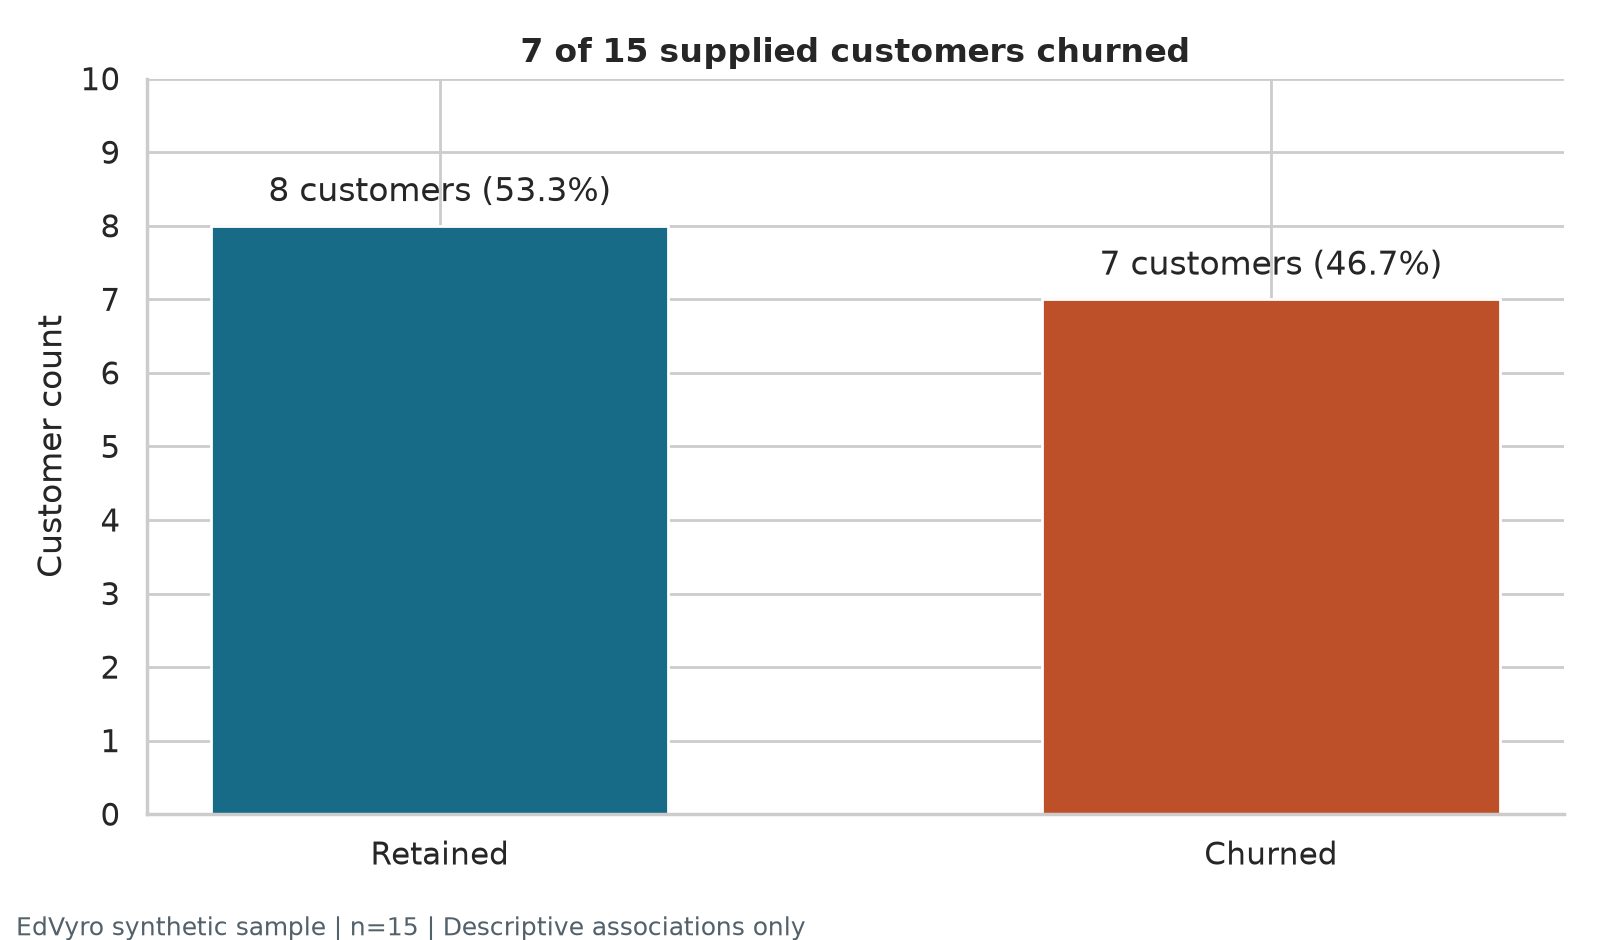

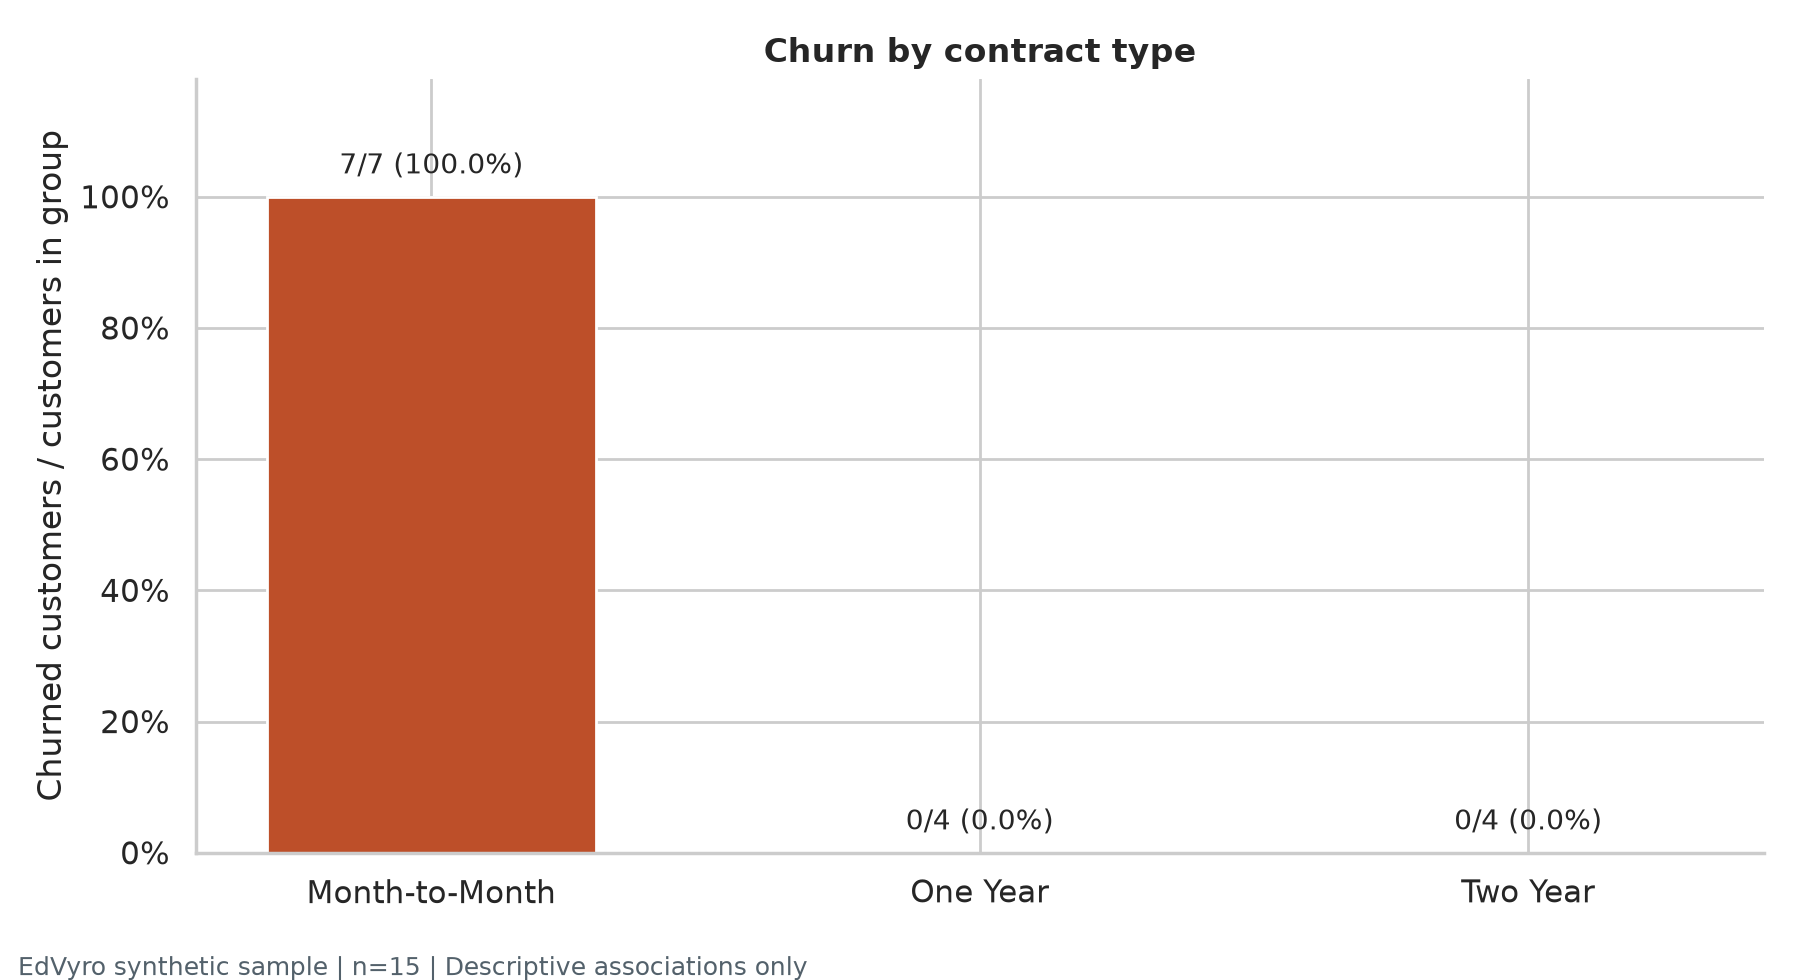

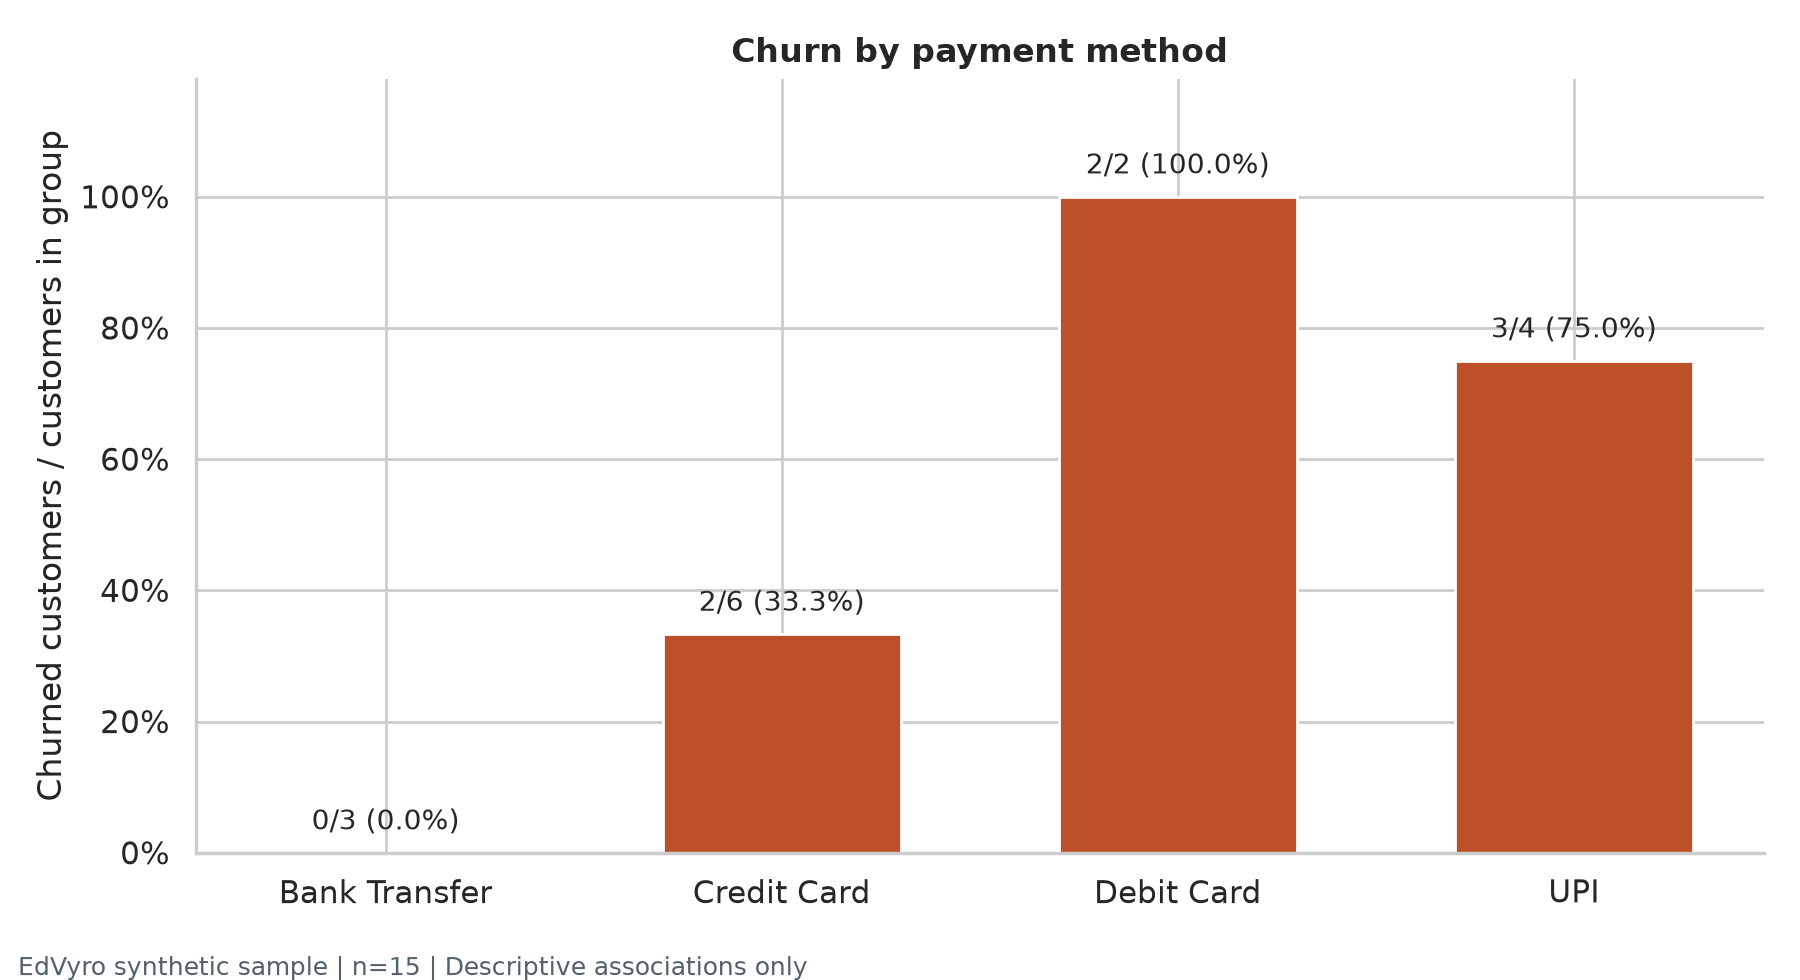

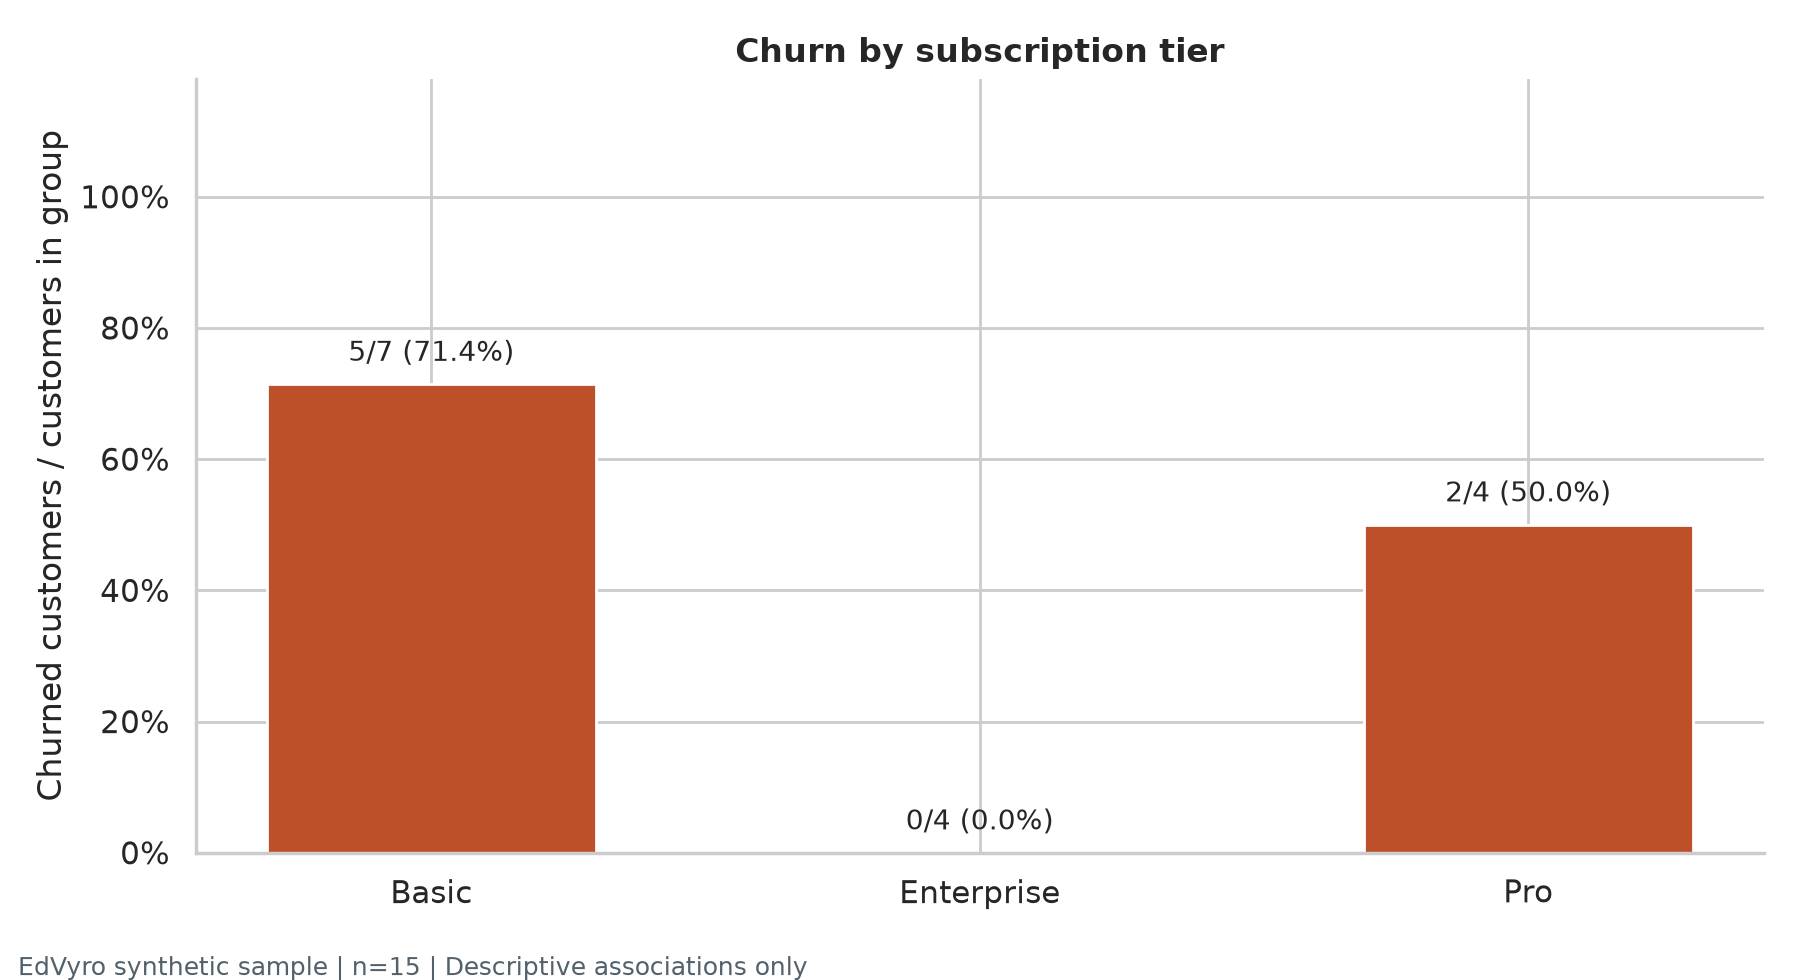

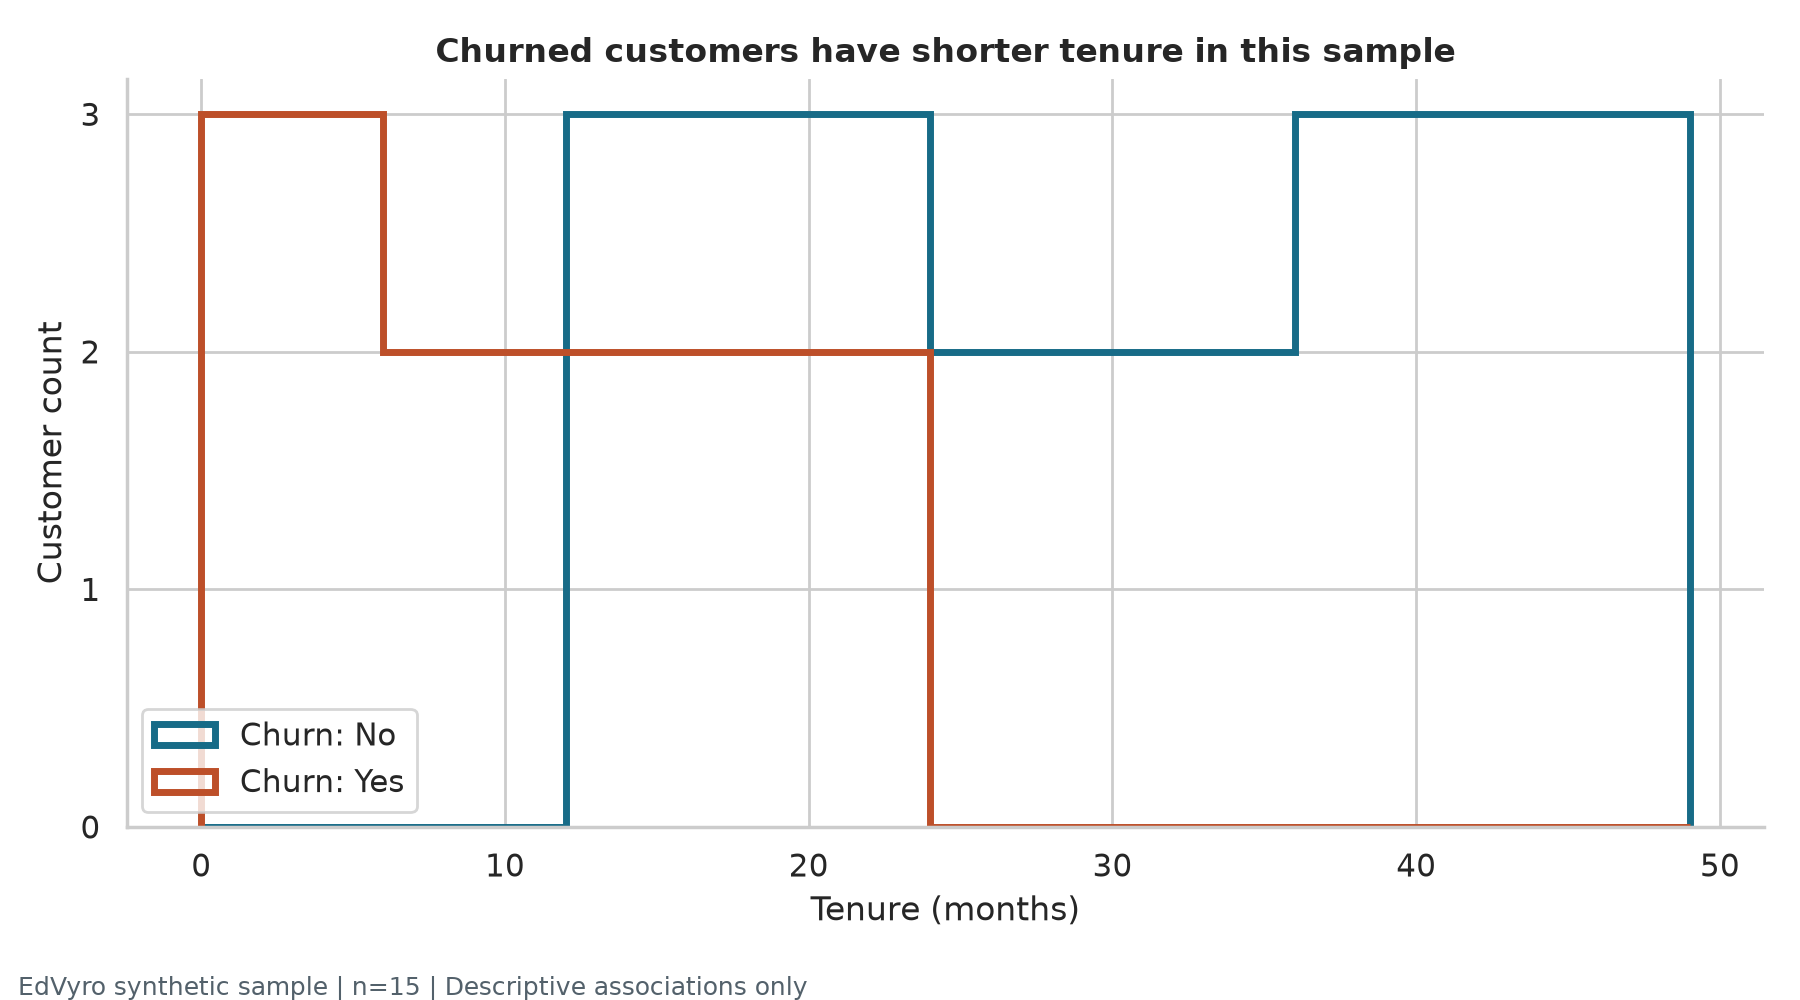

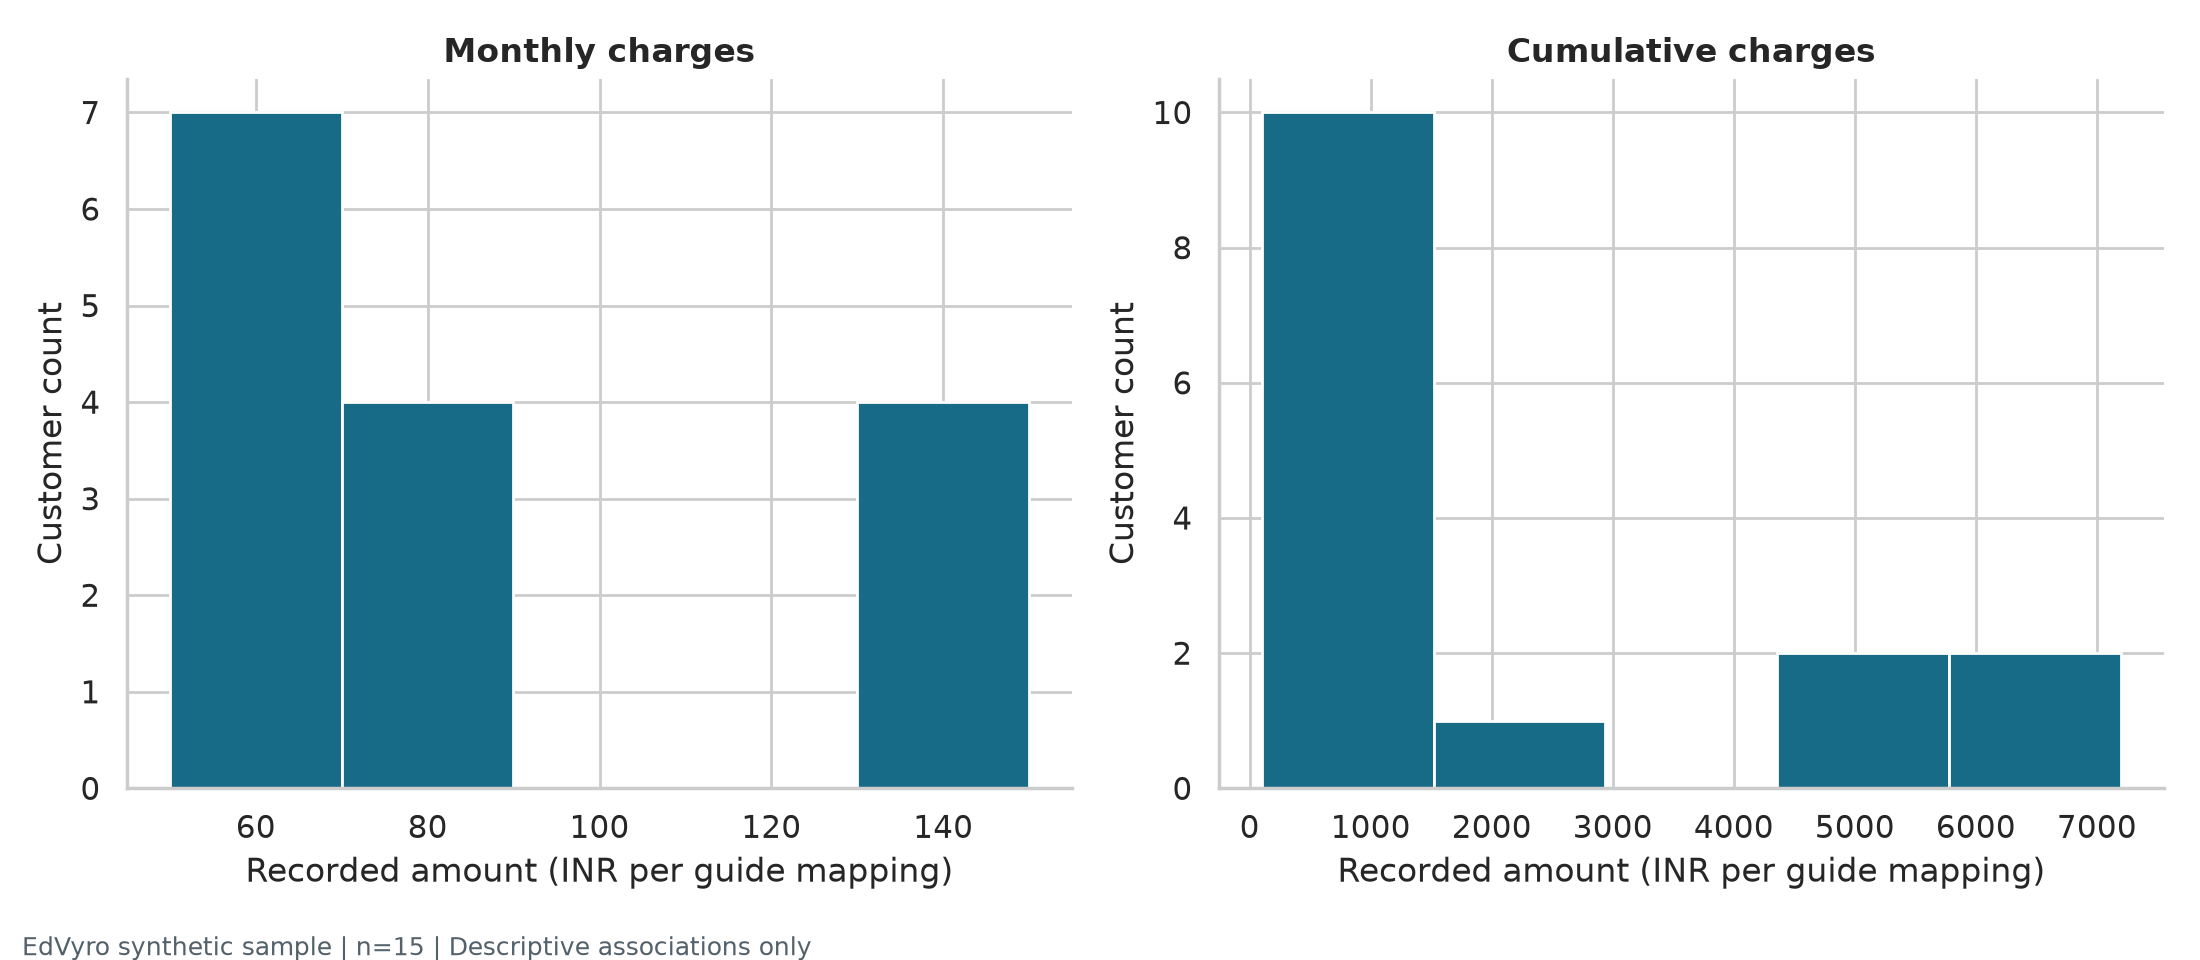

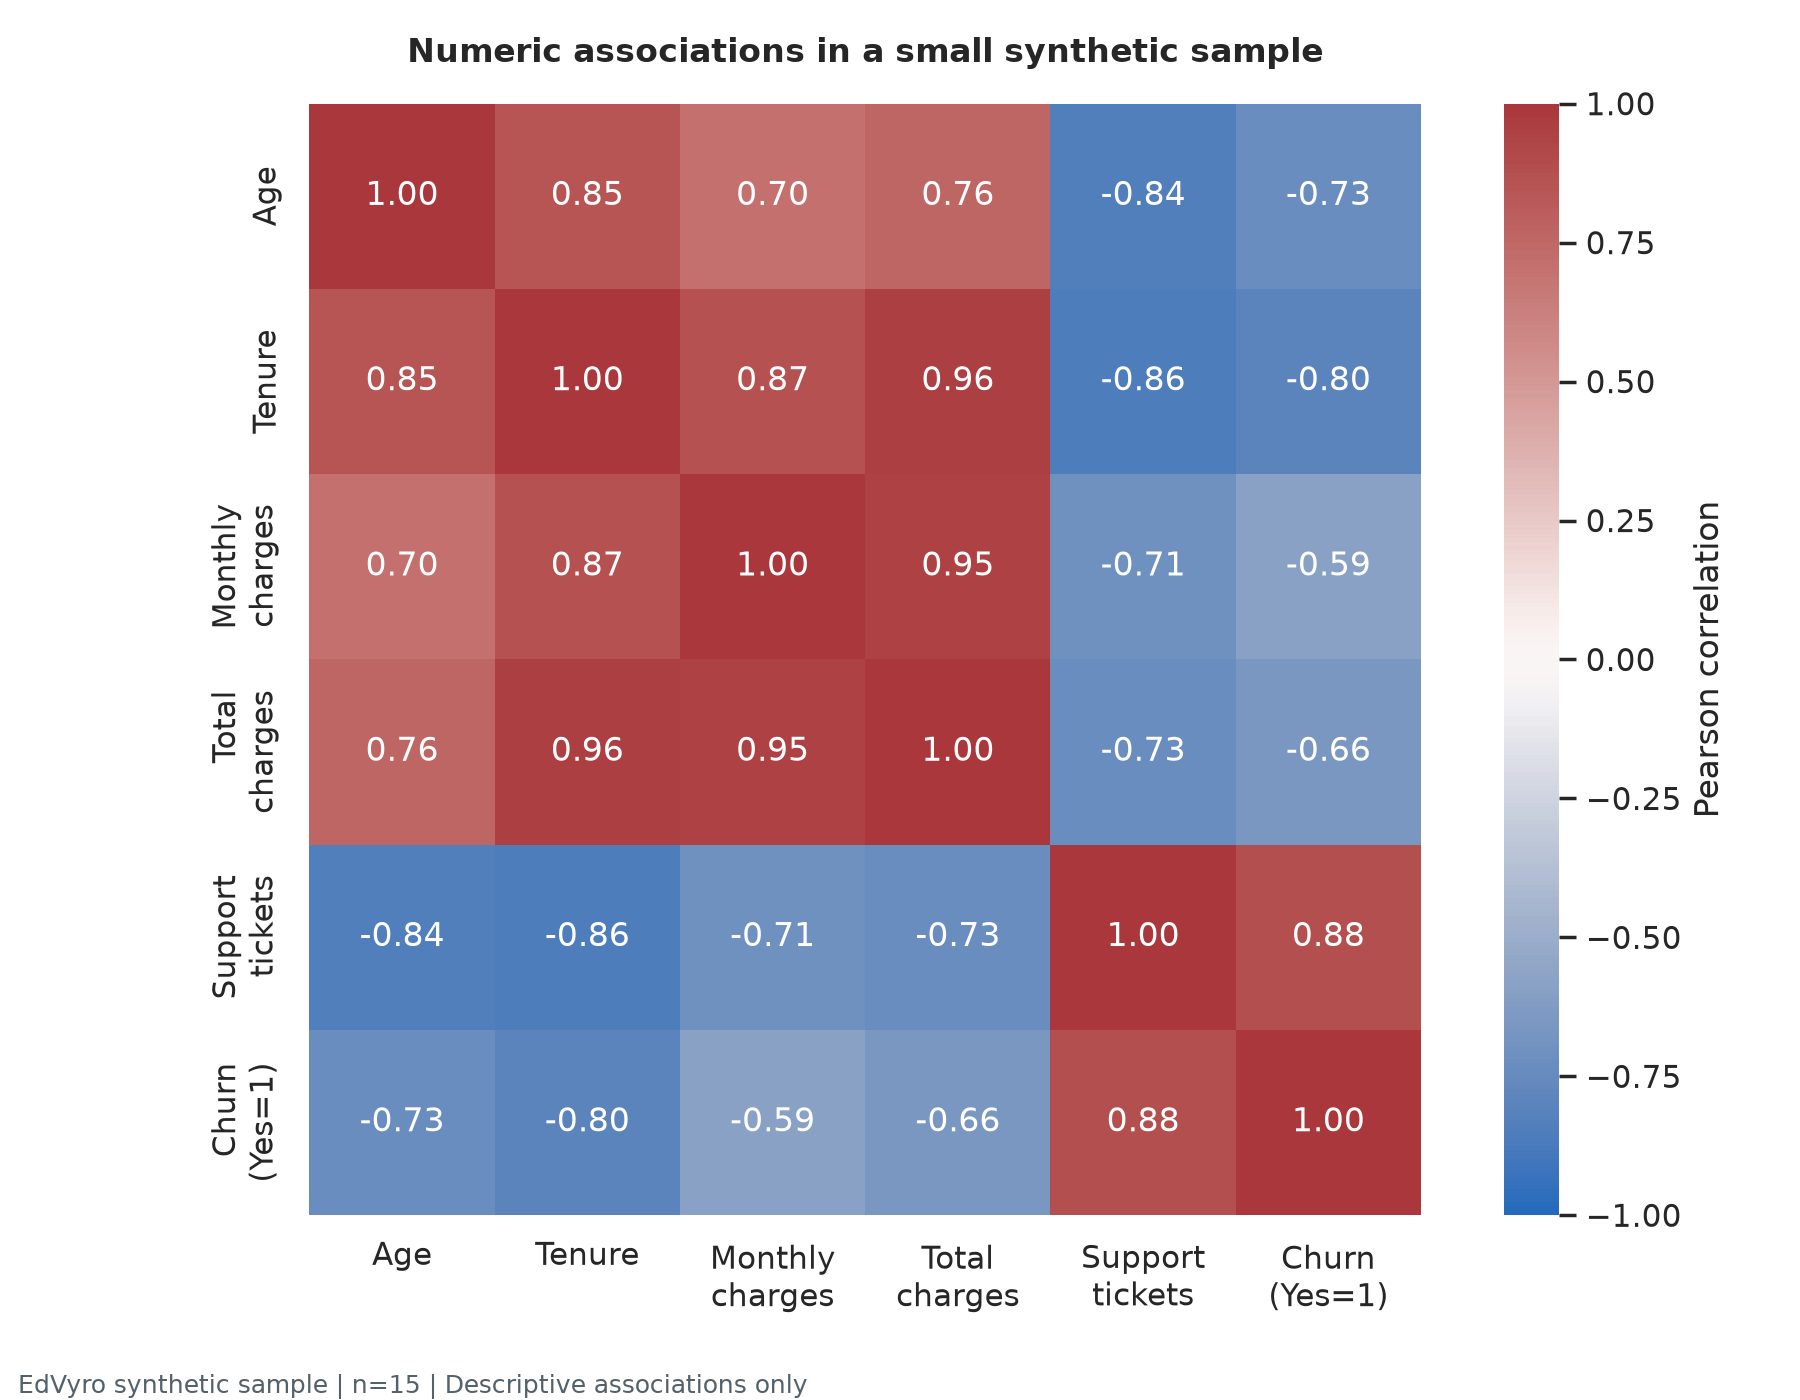

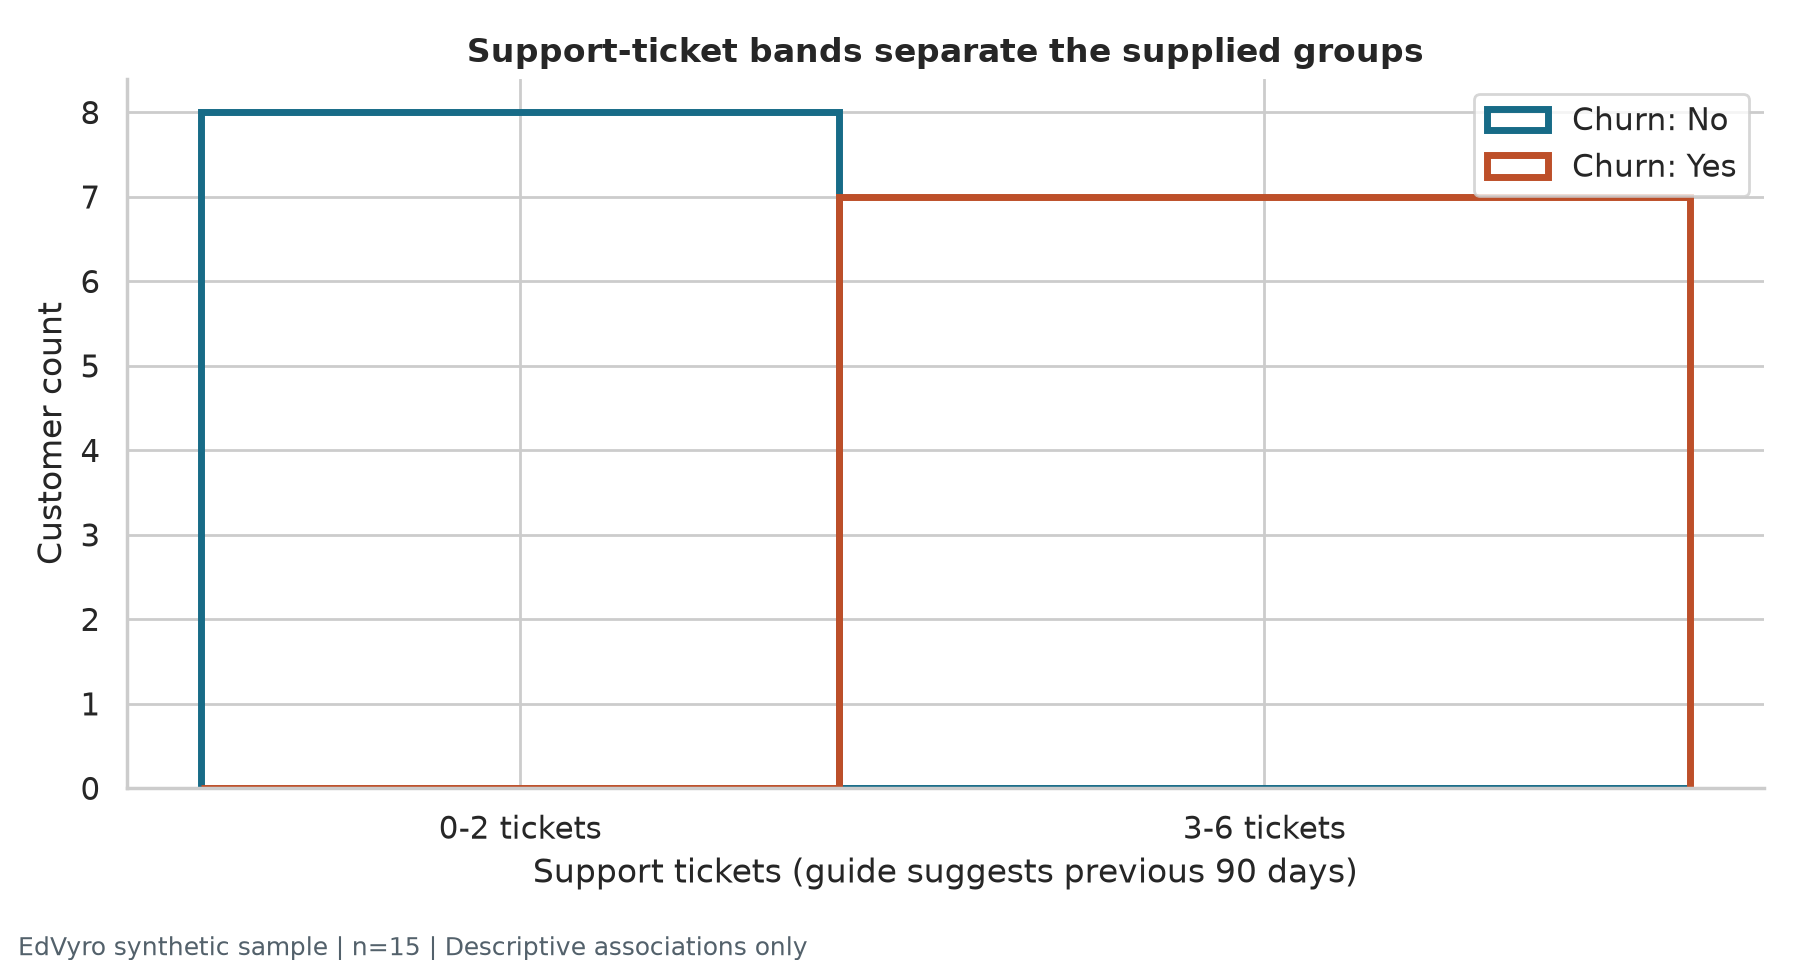

In [13]:
for name in FIGURES:
    display(Image(filename=str(ROOT / "figures" / name), width=850))

## 15. Key business insights

In [14]:
display(Markdown(findings(clean)))

- **Sample churn:** 7/15 customers (46.7%). The denominator is all supplied customers, not a monthly population.
- **Contract:** Month-to-Month has 7/7 churned (100.0%); the other contracts combined have 0/8 churned (0.0%). This perfect separation is a synthetic-sample limitation.
- **Tenure:** Mean tenure is 7.00 months for churned customers versus 29.12 for retained customers.
- **Support:** Churned customers average 4.29 tickets versus 1.00 for retained customers. The 3-or-more ticket band overlaps exactly with the churned group in this sample.
- **Spending and tier:** Mean monthly charges are 58.56 versus 107.49 for churned and retained customers respectively. Basic has 5/7 churned (71.4%). Tier, price, tenure, and contract overlap; none has an isolated estimated effect.

## 16. Limitations

In [15]:
display(Markdown(LIMITATIONS))

Only 15 synthetic records are supplied, with no sampling design, observation dates, churn window, or independent validation cohort. Rates describe this sample only. Perfect separation by contract and support-ticket band makes independent effects unidentifiable. Do not infer causes, deploy a prediction model, or estimate saved revenue. Individual service flags are absent; SubscriptionType is a tier, not a service inventory. The generic source guide has different field names and contract categories. INR and the 90-day ticket window are tentative guide mappings rather than CSV metadata. Billing history is unavailable, so TotalCharges = MonthlyCharges x TenureMonths is a descriptive sample consistency check, not a universal business rule.

## 17. Recommendations

In [16]:
display(Markdown(recommendations()))

For the fictional subscription retention team, prioritize a review of early-tenure, Month-to-Month accounts with repeated support contacts. The observed 100% churn in the monthly-contract sample and the support-group difference support a hypothesis for investigation, not an intervention effect. In a larger authorized dataset, record observation dates, contact eligibility, ticket reasons and resolution times, and collect prospective outcomes. Measure next-period churn and ticket resolution in eligible contacted and comparison groups, using a randomized pilot where practical. Do not target people on gender or claim changing contract or price will prevent churn. The data owner should reconcile the generic guide with the actual schema and confirm currency, ticket window, billing definitions, missing-value policy and sharing rights.

## 18. Conclusion
The supplied snapshot can support reproducible descriptive exploration under the documented assumptions. No artificial defects were introduced, and no valid records or targets were discarded. The separate automated tests exercise missing values, malformed categories/numbers, duplicates, preservation and reproducibility. See `reports/verification.md` for executed evidence and `reports/submission_checklist.md` for criterion status.

Public code, executed notebook, aggregate reports and figures are available for review. The mandatory cleaned CSV has been generated and validated locally, but its authorized delivery is still pending. A repository link alone does not complete that missing requirement.

Sources: [official curriculum](https://edvyro.in/internships/data-analytics), [task checklist](https://edvyro.in/datasets/task-kits/data-analytics-task-1), [analysis guide](https://edvyro.in/datasets/source-materials/task-source-library#analytics), [terms](https://edvyro.in/legal/terms).